2.1.1


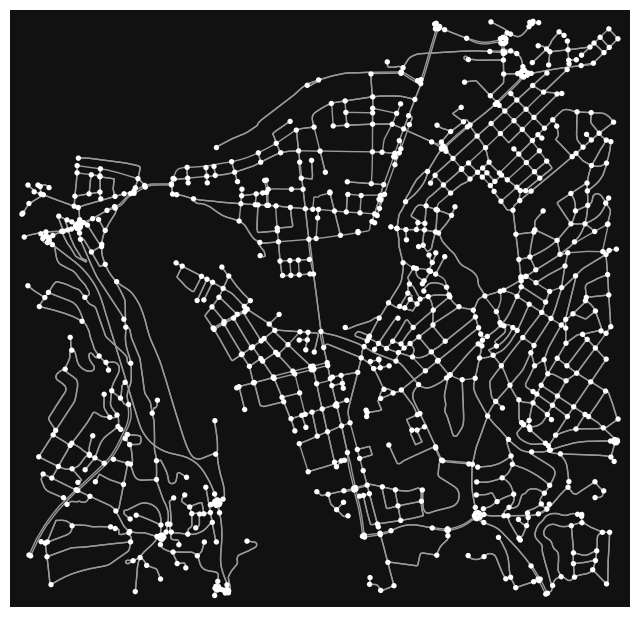

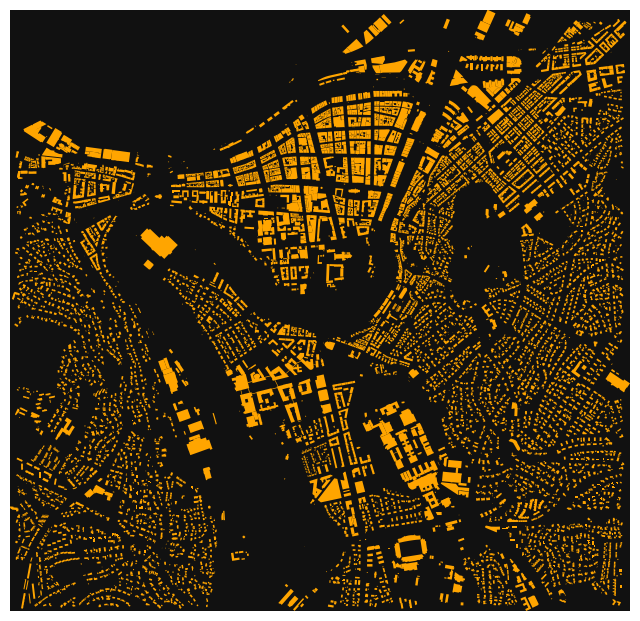

In [4]:
import osmnx as ox
print(ox.__version__)
# Bounding box (Trondheim)
north, south = 63.43854, 63.40951
east, west   = 10.42791, 10.36062
bbox = (west, south, east, north)  # osmnx >=2.0 order: (left, bottom, right, top)

# Street network
G = ox.graph_from_bbox(bbox, network_type='drive')
G = ox.distance.add_edge_lengths(G)
fig, ax = ox.plot_graph(G)

# Buildings
buildings = ox.features_from_bbox(bbox, tags={'building': True})
fig, ax = ox.plot_footprints(buildings)

In [12]:
import networkx as nx
import numpy as np
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components

Gm = ox.convert.to_undirected(G)

Gu = nx.Graph()
Gu.add_nodes_from(Gm.nodes(data=True))
for u, v, d in Gm.edges(data=True):
    if u == v:
        continue
    if not Gu.has_edge(u, v) or d['length'] < Gu[u][v]['length']:
        Gu.add_edge(u, v, length=d['length'])

nodes = list(Gu.nodes())
node_idx = {n: i for i, n in enumerate(nodes)}

# sparse adjacency, weighted by edge length (meters) -- this is a DISTANCE matrix
A_dist = nx.to_scipy_sparse_array(Gu, nodelist=nodes, weight='length', format='csr')
# Gaussian kernel: similarity = exp(-d^2 / 2*sigma^2), only on the nonzero (existing edge) entries
sigma = A_dist.data.mean()           # or median, or set manually (meters)
A_sim = A_dist.copy()
A_sim.data = np.exp(-(A_sim.data ** 2) / (2 * sigma ** 2))


D = sp.diags(np.asarray(A_sim.sum(axis=1)).ravel())
L = (D - A_sim).tocsr()

# Checks: L symmetric, L 1 = 0, number of connected components (= multiplicity of eigenvalue 0)
print(f"N = {L.shape[0]}, edges = {Gu.number_of_edges()}, sigma = {sigma:.1f} m")
print(f"max|L - L^T| = {abs(L - L.T).max():.2e},  max|L 1| = {np.abs(L @ np.ones(L.shape[0])).max():.2e}")
print(f"connected components = {connected_components(A_sim, directed=False)[0]}")
print(f"smallest degree = {D.diagonal().min():.2e}")

N = 949, edges = 1284, sigma = 89.7 m
max|L - L^T| = 0.00e+00,  max|L 1| = 5.55e-16
connected components = 1
smallest degree = 1.70e-13


In [19]:
import scipy.linalg as la
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.cluster import KMeans
from lanczos import lanczos_iteration

colors = ["#3FC38B", "#FF8C42", "#4DA3E0", "#F7B731", "#F26B6B",
          "#9B6BD6", "#E85D9E", "#B5E61D", "#A0522D", "#00CED1"]


def spectral_clustering_graph(L, K=4, method="eigh", m=300):
    '''
    Spectral clustering of a graph given by its Laplacian.

    Parameters:
        L: The graph Laplacian, scipy sparse matrix of shape (N,N)
        K: The number of clusters (default 4)
        method: "eigh" (scipy.linalg.eigh, dense reference) or "lanczos" (lanczos_iteration from lanczos.py)
        m: The number of Lanczos steps (only for method="lanczos")

    Return:
        C: The cluster labels, np.array of shape (N,)
        lambdas: The K smallest eigenvalues (Ritz values for Lanczos), np.array of shape (K,)
        U: The corresponding eigenvectors (Ritz vectors) as columns, np.array of shape (N,K)
    '''
    if method == "eigh":
        lambdas, V = la.eigh(L.toarray())
        lambdas, U = lambdas[:K], V[:, :K]
    else:
        lambdas, U, res = lanczos_iteration(L, m, K=K, reorth=True)
    C = KMeans(n_clusters=K, n_init=10, random_state=0).fit(U).labels_
    return C, lambdas, U


def plot_graph_clusters(G, C, node_idx, title="Spectral clustering", ax=None):
    '''
    Street network plotted as in ox.plot_graph, with the intersections coloured by cluster label.
    Roads between two intersections in the same cluster get the cluster colour, other roads stay grey.

    Parameters:
        G: The street network (osmnx MultiDiGraph)
        C: The cluster labels, np.array of shape (N,), ordered as node_idx
        node_idx: Dict from osmnx node id to row index of L
        title: The plot title
        ax: Optional matplotlib axes to plot in (e.g. one panel of a grid). If None, a new figure is shown
    '''
    palette = np.array(colors)
    c = lambda n: C[node_idx[n]]
    node_color = [palette[c(n) % len(palette)] for n in G.nodes()]
    edge_color = [palette[c(u) % len(palette)] if c(u) == c(v) else "#555555" for u, v in G.edges()]

    fig, ax_ = ox.plot_graph(G, ax=ax, node_color=node_color, node_size=15 if ax is None else 6,
                             edge_color=edge_color, edge_linewidth=1 if ax is None else 0.6,
                             show=False, close=False)
    ax_.set_facecolor("#111111")   # same dark background as ox.plot_graph, also inside a grid
    sizes = np.bincount(C)
    handles = [Line2D([], [], marker="o", ls="", color=palette[j % len(palette)],
                      label=f"Cluster {j + 1} ({sizes[j]} nodes)") for j in range(len(sizes))]
    if ax is None:
        ax_.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
        ax_.set_title(title, fontsize=14)
        plt.show()
    else:
        ax_.set_title(title, fontsize=11)

smallest eigenvalues: [-2.05456464e-16  1.69880171e-13  1.20838868e-07  2.99327224e-06]
cluster sizes: [939   7   1   2]


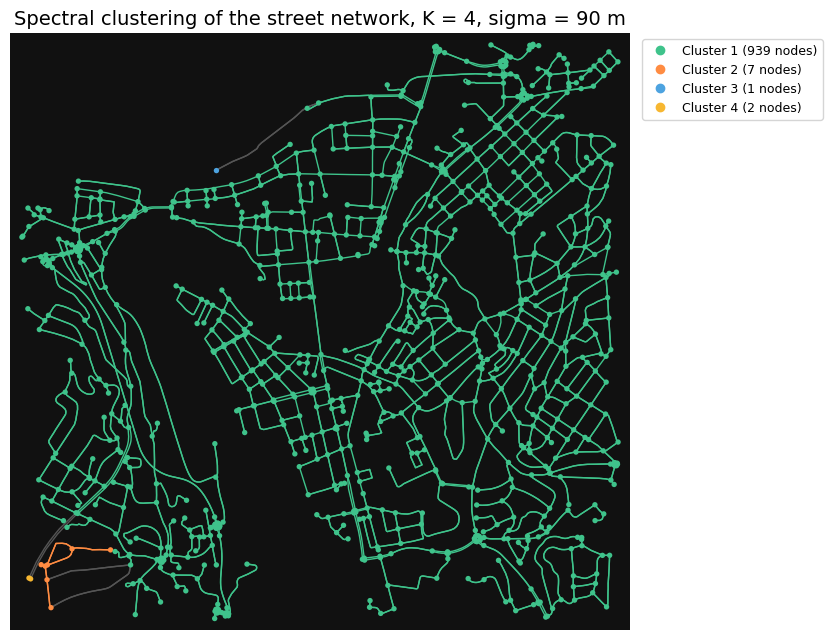

In [20]:
K = 4
C, lambdas, U = spectral_clustering_graph(L, K=K)
print("smallest eigenvalues:", lambdas)
print("cluster sizes:", np.bincount(C))
plot_graph_clusters(G, C, node_idx, title=f"Spectral clustering of the street network, K = {K}, sigma = {sigma:.0f} m")

### Choice of $\sigma$ and $K$
With $\sigma$ = mean edge length ($\approx 90$ m) the Gaussian weight of a long road is almost $0$ (a 688 m road gets $\approx 10^{-13}$), so single dead-end intersections are cut off and become their own clusters. For $\sigma \le 200$ m there is still always a cluster consisting of a single node. We therefore compare $\sigma = 300, 500, 1000$ m (the 99th percentile of the edge lengths is about 430 m, the longest edge 1670 m).

For $K$ we look at the eigengap: a jump between $\lambda_K$ and $\lambda_{K+1}$ means that the graph has $K$ well separated parts. Below, $K = 4$ (as before), $K = 7$ (the jump after $\lambda_7$) and $K = 10$.

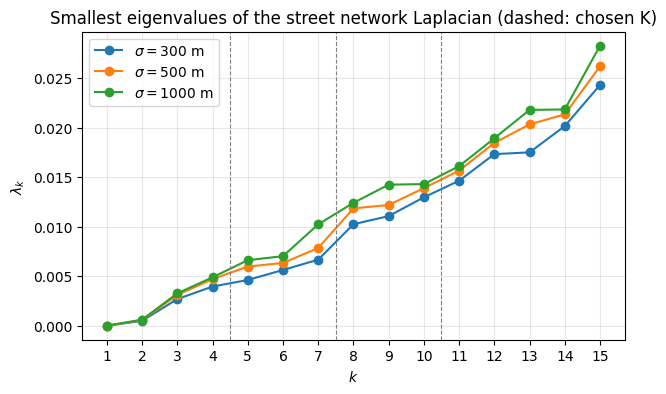

In [21]:
def street_laplacian(A_dist, sigma):
    '''
    Graph Laplacian L = D - W of the street network with Gaussian weights w_ij = exp(-d_ij^2 / (2 sigma^2))
    on the roads, where d_ij is the road length in meters.

    Parameters:
        A_dist: Sparse matrix of road lengths (meters), scipy sparse matrix of shape (N,N)
        sigma: The value of sigma (meters)

    Return:
        L: The Laplacian matrix, scipy sparse matrix of shape (N,N)
    '''
    W = A_dist.copy()
    W.data = np.exp(-(W.data ** 2) / (2 * sigma ** 2))
    D = sp.diags(np.asarray(W.sum(axis=1)).ravel())
    return (D - W).tocsr()


sigmas = [300, 500, 1000]
Ks = [4, 7, 10]

# Eigengap: the 15 smallest eigenvalues for each sigma
fig, ax = plt.subplots(figsize=(7, 4))
for s in sigmas:
    lambdas_s = la.eigh(street_laplacian(A_dist, s).toarray(), eigvals_only=True)[:15]
    ax.plot(np.arange(1, 16), lambdas_s, "o-", label=fr"$\sigma = {s}$ m")
for K in Ks:
    ax.axvline(K + 0.5, color="grey", ls="--", lw=0.8)
ax.set_xlabel("$k$")
ax.set_ylabel(r"$\lambda_k$")
ax.set_title("Smallest eigenvalues of the street network Laplacian (dashed: chosen K)")
ax.set_xticks(np.arange(1, 16))
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [ ]:
# Spectral clustering for every combination of sigma (rows) and K (columns)
fig, axes = plt.subplots(len(sigmas), len(Ks), figsize=(18, 18))
for row, s in zip(axes, sigmas):
    L_s = street_laplacian(A_dist, s)
    for ax, K in zip(row, Ks):
        C_s, _, _ = spectral_clustering_graph(L_s, K=K)
        print(f"sigma = {s:4d} m, K = {K:2d}: cluster sizes {sorted(np.bincount(C_s))}")
        plot_graph_clusters(G, C_s, node_idx, title=fr"$\sigma = {s}$ m, $K = {K}$", ax=ax)
fig.tight_layout()
plt.show()

sigma =  300 m, K =  4: cluster sizes [np.int64(98), np.int64(139), np.int64(295), np.int64(417)]


**Observations.** For all three values of $\sigma$ the clusters are connected parts of the city, and the boundaries (grey roads) lie where only few roads connect two areas, mostly at the river crossings. $\sigma = 500$ m and $\sigma = 1000$ m give almost the same clusters for every $K$ (for $K = 4$: 125, 211, 222, 391 against 125, 212, 222, 390 nodes), because for $\sigma \ge 500$ m almost all weights are close to 1 and the graph is effectively unweighted. With $\sigma = 300$ m the longer roads are weaker, which already changes the $K = 4$ clustering (98, 139, 295, 417 nodes).

For $K = 7$ and $K = 10$ two small clusters of about 22 and 30 intersections appear for every $\sigma$: areas that are attached to the rest of the network by only one or two roads. The eigengap is not very pronounced (the eigenvalues grow almost linearly after $\lambda_3$), with the clearest jumps after $\lambda_2$ (a factor of about 5) and after $\lambda_7$ (a factor of about 1.5). $K = 7$ with $\sigma = 500$ m is therefore a reasonable choice, but the data do not single out one "correct" number of clusters.